In [15]:
# Import necessary libraries
import os
import sys
# Add the utils folder to the system path so we can import custom modules
sys.path.append(os.path.abspath(os.path.join("../..")))
import matplotlib.pyplot as plt
import torch
import numpy as np
import torch.nn as nn
import pandas as pd
from utils.reproducibility_utils import seed_everything
from utils.data_loading import load_data, load_test_data, feature_names

# Set the plotting style for better-looking visualizations
plt.style.available
plt.style.use('seaborn-v0_8')

In [16]:
print("Loading train data...")
train_dataloader, val_dataloader, pipeline = load_data(
    train_path = "../../datasets_challenge/train",  # Path to training data
    train_ratio = 0.98,  # Use 98% for training, 2% for validation
    batchsize = 64,  # Number of samples per batch
    # columns_to_standardize = feature_names,  # Option to specify which columns to standardize
    columns_to_drop = ["sideSlip", "vyCG", "time", "longitude","latitude"],  # Remove these from features
    sequence_length = 20,  # Number of time steps in each sequence (t-19 to t0)
    threshold = True,  # Enable velocity thresholding
    threshold_value = 3.0,  # Only keep samples where vehicle speed > 3 m/s
    threshold_column = "vxCG",  # Column to apply threshold on (longitudinal velocity)
    target = "sideSlip",  # The variable we want to predict
    scaling = True,  # Apply standardization to features
    seed = 42,  # Random seed for train/val split
)

Loading train data...
../../datasets_challenge/train\train_part_001.csv
../../datasets_challenge/train\train_part_002.csv
../../datasets_challenge/train\train_part_003.csv
../../datasets_challenge/train\train_part_004.csv
../../datasets_challenge/train\train_part_005.csv
../../datasets_challenge/train\train_part_006.csv
../../datasets_challenge/train\train_part_007.csv
../../datasets_challenge/train\train_part_008.csv
../../datasets_challenge/train\train_part_009.csv
../../datasets_challenge/train\train_part_010.csv
../../datasets_challenge/train\train_part_011.csv
../../datasets_challenge/train\train_part_012.csv
../../datasets_challenge/train\train_part_013.csv
../../datasets_challenge/train\train_part_014.csv
../../datasets_challenge/train\train_part_015.csv
../../datasets_challenge/train\train_part_016.csv
../../datasets_challenge/train\train_part_017.csv
../../datasets_challenge/train\train_part_018.csv
../../datasets_challenge/train\train_part_019.csv
../../datasets_challenge/tra

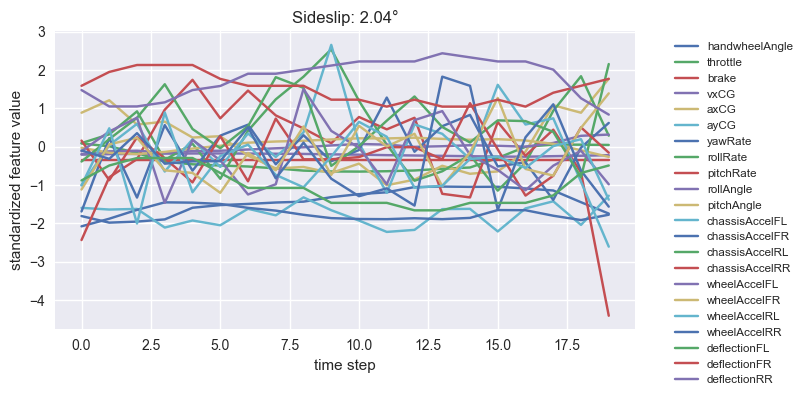

In [17]:
# Get one batch of data from the training dataloader
X, y = next(iter(train_dataloader))

# Visualize the first sample in the batch
plt.figure(figsize=(8,4))
plt.plot(X[0,:,:], label=feature_names)  # Plot all 22 features over 20 time steps
plt.title("Sideslip: "+str(round(y[0].item(),2))+"°")  # Show the target value
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize='small')
plt.tight_layout()
plt.xlabel("time step")
plt.ylabel("standardized feature value")
plt.show()

In [18]:
class RNN(nn.Module):
    """
    Recurrent Neural Network for sideslip angle prediction.
    
    Architecture:
    1. RNN Layer - Processes sequential input
    2. Fully Connected Layer - Transforms RNN output
    3. Output Layer - Produces final prediction
    
    Dropout layers are included to prevent overfitting.
    """
    def __init__(self, input_size, output_size=1, rnn_units=28, fc_units=28, 
                 activation_fct=nn.ReLU(), dropout=[0.0, 0, 0], rnn_nonlinearity='relu'):
        super(RNN, self).__init__()
        
        # RNN layer: processes the sequence and captures temporal dependencies
        self.rnn_layer = nn.RNN(input_size=input_size, hidden_size=rnn_units, 
                                num_layers=1, nonlinearity=rnn_nonlinearity, batch_first=True)
        
        # Fully connected layers for processing RNN output
        self.fc = nn.Linear(rnn_units, fc_units)
        self.output_layer = nn.Linear(fc_units, output_size)
        
        # Dropout layers to prevent overfitting (randomly zeros out neurons during training)
        self.dropout1 = nn.Dropout(dropout[0])  # Applied to input
        self.dropout2 = nn.Dropout(dropout[1])  # Applied after RNN
        self.dropout3 = nn.Dropout(dropout[2])  # Applied after FC layer
        
        self.activation_fct = activation_fct
 
    def forward(self, x):
        # x shape: (batch_size, sequence_length, input_size)
        x = self.dropout1(x)
        
        # Process sequence through RNN
        x, _ = self.rnn_layer(x)  # Output shape: (batch_size, sequence_length, rnn_units)
        
        # Take only the last time step's output (t0)
        x = x[:, -1, :]  # Shape: (batch_size, rnn_units)
        
        x = self.dropout2(x)
        x = self.activation_fct(self.fc(x))  # Apply fully connected layer with activation
        x = self.dropout3(x)
        x = self.output_layer(x)  # Final prediction
        
        return x

In [19]:
import copy
import torch
import torch.nn as nn
import numpy as np

def train_rnn_with_seed(
    seed,
    train_dataloader,
    input_size,
    device="cpu",
    epochs=20,
    lr=0.0003
):
    # set seed
    seed_everything(seed)

    # create model
    model = RNN(
        input_size=input_size,
        output_size=1,
        rnn_units=48,
        fc_units=48,
        dropout=[0.0, 0.0, 0.0]
    ).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.L1Loss()

    # training loop
    for epoch in range(epochs):
        model.train()
        epoch_loss = 0.0

        for X, y in train_dataloader:
            X = X.to(device)
            y = y.to(device).unsqueeze(1)

            optimizer.zero_grad()
            preds = model(X)
            loss = criterion(preds, y)
            loss.backward()
            optimizer.step()

            epoch_loss += loss.item()

        print(f"[Seed {seed}] Epoch {epoch+1}/{epochs} | "
              f"Loss: {epoch_loss/len(train_dataloader):.4f}")

    return model


In [20]:
device = "cpu"  # or "cuda"

ENSEMBLE_SEEDS = [1, 2, 3]
EPOCHS = 20

input_size = X.shape[2]  # number of features per timestep

ensemble_models = []

for seed in ENSEMBLE_SEEDS:
    model = train_rnn_with_seed(
        seed=seed,
        train_dataloader=train_dataloader,
        input_size=input_size,
        device=device,
        epochs=EPOCHS
    )
    ensemble_models.append(model)


[Seed 1] Epoch 1/20 | Loss: 0.2880
[Seed 1] Epoch 2/20 | Loss: 0.1981
[Seed 1] Epoch 3/20 | Loss: 0.1841
[Seed 1] Epoch 4/20 | Loss: 0.1754
[Seed 1] Epoch 5/20 | Loss: 0.1698
[Seed 1] Epoch 6/20 | Loss: 0.1661
[Seed 1] Epoch 7/20 | Loss: 0.1629
[Seed 1] Epoch 8/20 | Loss: 0.1603
[Seed 1] Epoch 9/20 | Loss: 0.1580
[Seed 1] Epoch 10/20 | Loss: 0.1560
[Seed 1] Epoch 11/20 | Loss: 0.1547
[Seed 1] Epoch 12/20 | Loss: 0.1527
[Seed 1] Epoch 13/20 | Loss: 0.1516
[Seed 1] Epoch 14/20 | Loss: 0.1497
[Seed 1] Epoch 15/20 | Loss: 0.1485
[Seed 1] Epoch 16/20 | Loss: 0.1477
[Seed 1] Epoch 17/20 | Loss: 0.1467
[Seed 1] Epoch 18/20 | Loss: 0.1456
[Seed 1] Epoch 19/20 | Loss: 0.1448
[Seed 1] Epoch 20/20 | Loss: 0.1438
[Seed 2] Epoch 1/20 | Loss: 0.2929
[Seed 2] Epoch 2/20 | Loss: 0.1956
[Seed 2] Epoch 3/20 | Loss: 0.1806
[Seed 2] Epoch 4/20 | Loss: 0.1719
[Seed 2] Epoch 5/20 | Loss: 0.1668
[Seed 2] Epoch 6/20 | Loss: 0.1628
[Seed 2] Epoch 7/20 | Loss: 0.1605
[Seed 2] Epoch 8/20 | Loss: 0.1579
[Seed 2] 

In [27]:
def predict_rnn(model, dataloader, device="cpu"):
    model.eval()
    preds = []

    with torch.no_grad():
        for X, _ in dataloader:
            X = X.to(device)
            preds.append(model(X).cpu().numpy())

    return np.concatenate(preds).ravel()


In [28]:
def ensemble_predict(models, dataloader, device="cpu"):
    all_preds = []

    for model in models:
        preds = predict_rnn(model, dataloader, device)
        all_preds.append(preds)

    return np.mean(all_preds, axis=0)


In [30]:
print("\nLoading test data...")
test_dataloader = load_test_data(test_path = "../../datasets_challenge/test",
                                 batchsize = 64,
                                 pipeline = pipeline, 
                                 load_anonymized_data=True)


Loading test data...
../../datasets_challenge/test\test_part_001.csv
../../datasets_challenge/test\test_part_002.csv
../../datasets_challenge/test\test_part_003.csv
../../datasets_challenge/test\test_part_004.csv
../../datasets_challenge/test\test_part_005.csv
../../datasets_challenge/test\test_part_006.csv
../../datasets_challenge/test\test_part_007.csv
../../datasets_challenge/test\test_part_008.csv
../../datasets_challenge/test\test_part_009.csv
../../datasets_challenge/test\test_part_010.csv
../../datasets_challenge/test\test_part_011.csv


In [31]:
import numpy as np

# Put all models in eval mode
for model in ensemble_models:
    model.eval()

test_preds = []

with torch.no_grad():
    for X, _ in test_dataloader:
        X = X.to(device)

        # collect predictions from each model
        batch_preds = []
        for model in ensemble_models:
            pred = model(X)
            batch_preds.append(pred.cpu().numpy())

        # average across models
        batch_preds = np.mean(batch_preds, axis=0)

        test_preds.append(batch_preds.reshape(-1))


In [32]:
test_preds = np.concatenate(test_preds)
print("Shape of Predictions:", test_preds.shape)

Shape of Predictions: (49328,)


In [33]:
import pandas as pd

y_pred = pd.DataFrame({
    "predicted_sideslip": test_preds,
    "id": range(len(test_preds))
})

y_pred.to_csv("predictionsAVG3.csv", index=False)

print("✓ Predictions saved to 'predictionsAVG3.csv'")
print(f"✓ Total samples: {len(test_preds)}")
print("✓ Ready for submission to the competition!")

✓ Predictions saved to 'predictionsAVG3.csv'
✓ Total samples: 49328
✓ Ready for submission to the competition!
